
 Notebook d'exploration des données de tweets

In [1]:
# Import the requiered libraries
import os
import sys
import logging
from matplotlib.pyplot import ylabel
import missingno as msno
from tqdm.notebook import tqdm

import pandas as pd
import numpy as np
import re
import nltk.stem

from sklearn.feature_extraction import text
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import plot_confusion_matrix

%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import shap
shap.initjs()


In [2]:
# Define constants
FILE_TWEETS = 'sentiment140\\training.1600000.processed.noemoticon.csv'
FILE_DF_TRAIN = 'df_train'
FILE_DF_VALIDATE = 'df_validate'
FILE_DF_TEST = 'df_test'
FILE_DF_BoW = 'df_bow.pkl'

# When prototype COEF = 0.1. Otherwhize = 1
COEF = 0.1

# Setup the logging
logging.basicConfig(stream= sys.stdout)


In [3]:
# Read the dataframes
path = os.getcwd() + '\\data\\'

df_train = pd.read_pickle(path + FILE_DF_TRAIN + f"-{COEF}.pkl")
df_bow = pd.read_pickle(path + FILE_DF_BoW)



In [4]:
# perform an PCA
sc = StandardScaler()
df_bow_train = sc.fit_transform(df_bow.loc[df_train.index])

pca = PCA(
            n_components= 0.95
)
pca.fit(df_bow_train)
n_dimension = 10
X = pca.transform(df_bow_train)[:,:n_dimension]


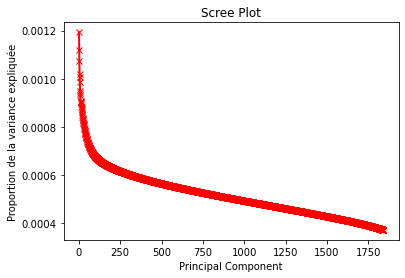

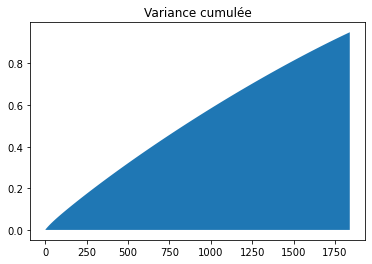

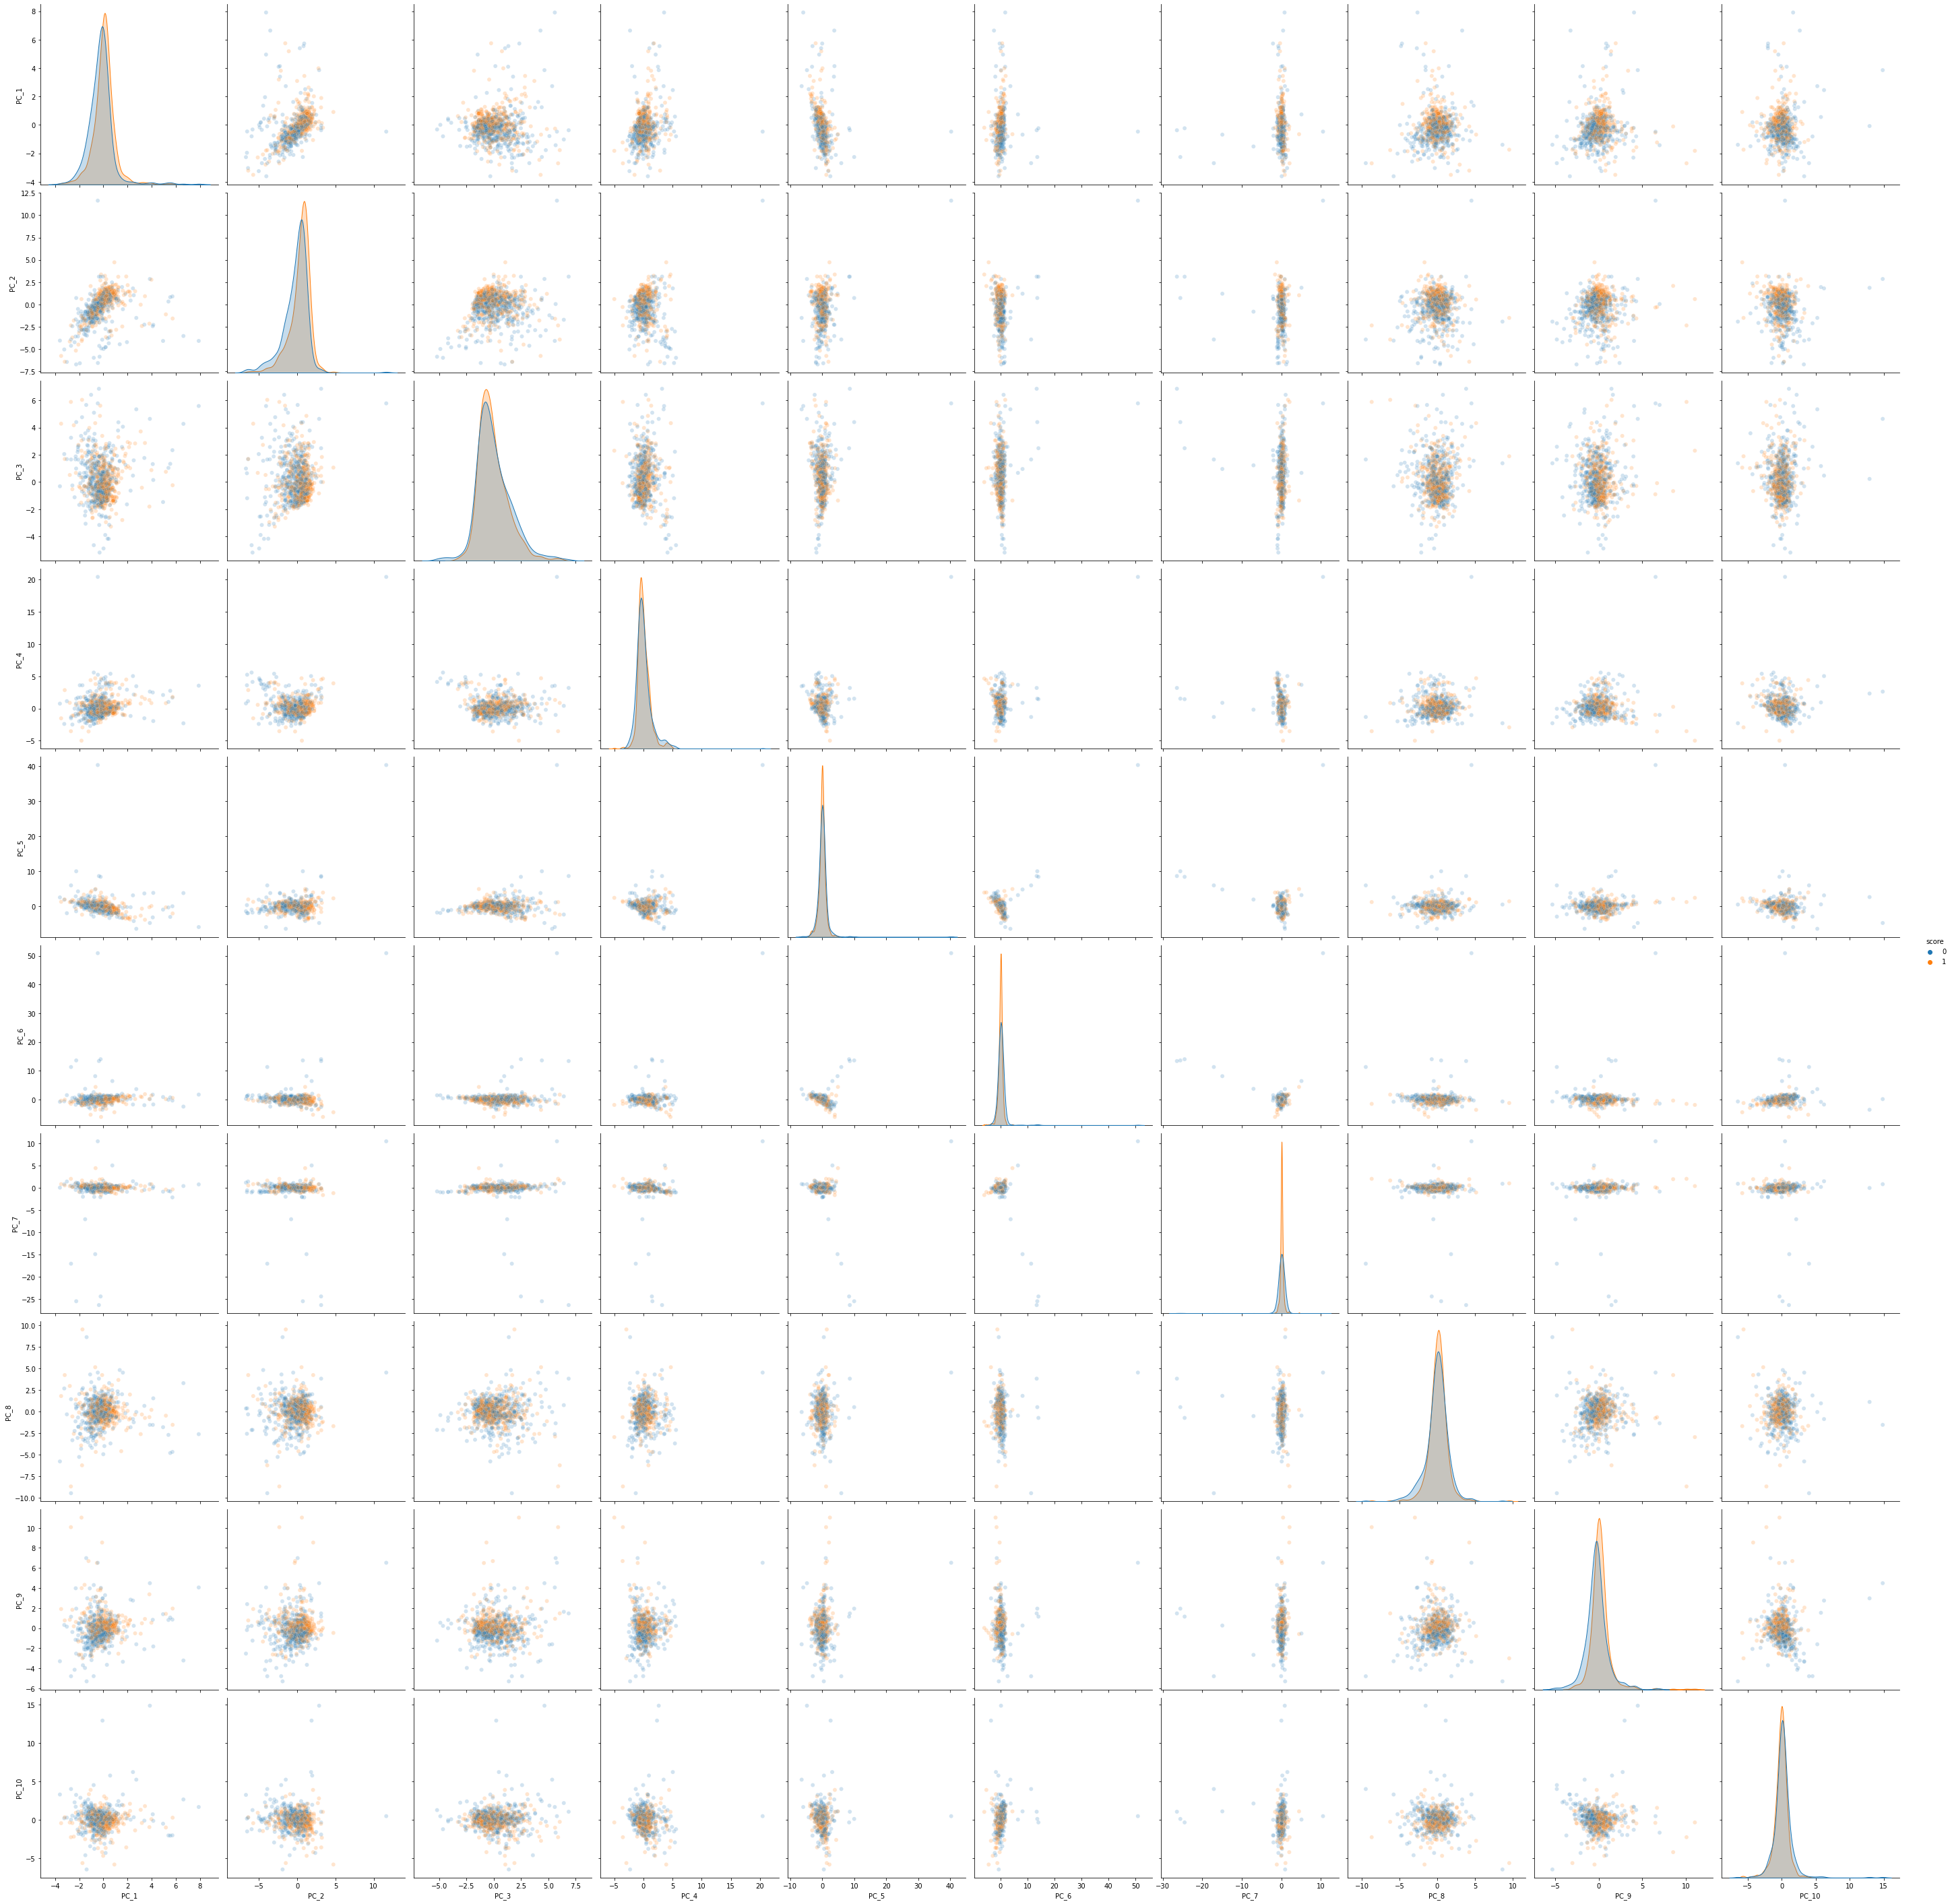

In [5]:
# Analyse the PCA
# Draw the scree plot
PC_values = np.arange(pca.n_components_) + 1
plt.plot(PC_values, pca.explained_variance_ratio_, 'rx-', linewidth=2)
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Proportion de la variance expliquée')
plt.show()

# See how the variance is evolving
exp_var_cumul = np.cumsum(pca.explained_variance_ratio_)
plt.fill_between(np.arange(len(exp_var_cumul)), exp_var_cumul)
plt.title('Variance cumulée')
plt.show()

# Project on the axes and planes
tmp_df = pd.DataFrame(
                        data= X,
                        columns= [f'PC_{i+1}' for i in range(n_dimension)],
                        index= df_train.index
)
tmp_df['score'] = df_train['score']
# Take only part of it for the plot
tmp_df_sample = tmp_df.sample(
                                n= 1_000,
                                random_state= 23,
                                replace= False,
) 
sns.pairplot(
                data= tmp_df_sample,
                hue= 'score',
                plot_kws= {'alpha' : 0.2},
                height= 4,

)


Compute PCA:   0%|          | 0/11 [00:00<?, ?it/s]

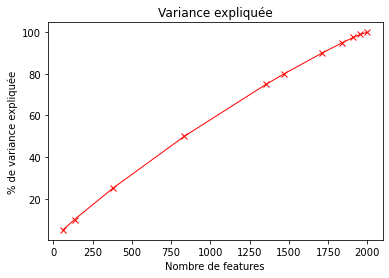

In [6]:
# Look at the variance explained vs size of PC
to_explain = [
                5, 10, 25, 50, 
                75, 80, 90, 95, 97.5, 99, 
                None
]
progress_bar = tqdm(
                    total= len(to_explain),
                    desc= 'Compute PCA',
                    leave= False
)
results = []
for percent in to_explain[:-1]:
    pca = PCA(
                n_components= percent / 100,
    )
    pca.fit(df_bow_train)
    results.append(len(pca.components_))
    progress_bar.update()
pca = PCA(n_components= len(df_bow.columns))
pca.fit(df_bow_train)
results.append(len(pca.components_))
progress_bar.update()
progress_bar.close()
plt.plot(
            results,
            to_explain[:-1] + [100],
            'rx-',
            linewidth= 1
)
plt.title(f"Variance expliquée")
plt.xlabel(f"Nombre de features")
plt.ylabel(f"% de variance expliquée")
plt.show()



Le score avec les paramètre de base est 0.662119087084024.


The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, or maskers.Impute)


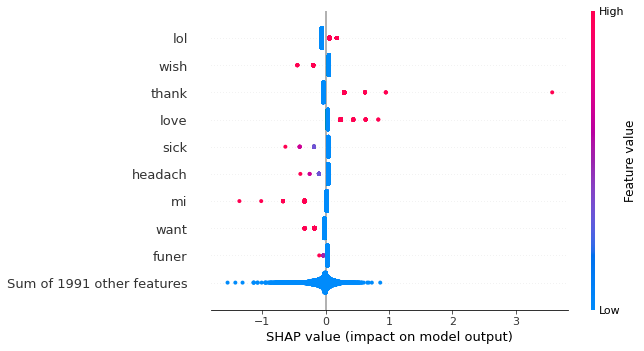

In [7]:
# Compute a logistic regression
# define the validations bow to test the training
df_validate = pd.read_pickle(path + FILE_DF_VALIDATE + f"-{COEF}.pkl")
df_bow_validate = df_bow.loc[df_validate.index]
# first model
lr = LogisticRegression()
model = lr.fit(df_bow_train, df_train['score'])
logging.info("Fit de la réfression Logistic réalisée")
score = model.score(df_bow_validate, df_validate['score'])
print(f"Le score avec les paramètre de base est {score}.")

explainer = shap.Explainer(
                            model,
                            df_bow_train,
                            feature_names= df_bow.columns
)
shap_values = explainer(df_bow_validate)
shap.plots.beeswarm(shap_values)#, df_bow_validate, feature_names= df_bow_train.columns)

ind = 5
shap.plots.force(shap_values[ind])
del(model)
del(explainer)


In [8]:
# LogisticCV (take a sample due to memmory constraints)
sample_coef = 0.1
sample = df_train.sample(
                            n= int(sample_coef * len(df_train)),
                            replace= False
).index
df_bow_train = pd.DataFrame(
                            data= df_bow_train,
                            columns= df_bow.columns,
                            index= df_train.index
)
clf = LogisticRegressionCV(
                            cv= 5,
                            random_state= 23,
                            n_jobs= -1,
                            verbose= 5,
).fit(df_bow_train.loc[sample], df_train.loc[sample, 'score'])
print(f"Nous avons un score de {clf.score(df_bow_validate, df_validate['score'])}")



[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:   41.5s remaining:  1.0min
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:   44.4s finished


Nous avons un score de 0.6638084916486039


GridSearchCV:   0%|          | 0/8 [00:00<?, ?it/s]

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Fitting 5 folds for each of 2 candidates, totalling 10 fits


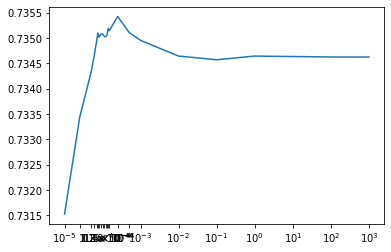

In [9]:
# Optimize the hyper-parameters
param_grid_ = [
                {'C': [1e-5, 2.5E-5, 5E-5]},
                {'C': [6E-5, 7E-5, 7.5E-5]},
                {'C': [8E-5, 9E-5, 1e-4]},
                {'C': [1.1E-4, 1.2E-4, 1.3E-4]},
                {'C': [1.4E-4, 1.5E-4, 2.5E-4]},
                {'C': [5E-4, 1E-3, 1e-2]},
                {'C': [1E-1, 1, 10]},
                {'C': [1E2, 1E3]},
]
results = {
            'score_mean' : [],
            'score_std'  : [],
            'params'     : []
}
progress_bar = tqdm(
                    total= len(param_grid_),
                    desc= 'GridSearchCV',
                    leave= False
)
for iteration in range(len(param_grid_)):
    bow_search = GridSearchCV(
                                LogisticRegression(), 
                                cv=5, 
                                param_grid=param_grid_[iteration],
                                verbose= 1,
                                n_jobs= 4,
    ).fit(df_bow_train, df_train['score'])
    [results['score_mean'].append(x) for x in bow_search.cv_results_['mean_test_score']]
    [results['score_std'].append(x)  for x in bow_search.cv_results_['std_test_score']]
    [results['params'].append(x)     for x in bow_search.cv_results_['params']]
    logging.info(f"{iteration} batch fait")
    progress_bar.update()
progress_bar.close()
df_results = pd.DataFrame(results)
df_results['param'] = [x['C'] for x in df_results['params']]
df_results.sort_values(by= 'param', inplace= True)
fig, ax = plt.subplots()
ax.plot(
        [x['C'] for x in df_results['params']],
        df_results['score_mean'],
)
ax.set_xscale('log')
ax.set_xticks([x['C'] for x in df_results['params']])
plt.show()


In [10]:
df_results.sort_values(by= 'score_mean', ascending= False)

,score_mean,score_std,params,param
14,0.735429,0.002547,{'C': 0.00025},0.000250
12,0.735192,0.002737,{'C': 0.00014},0.000140
13,0.735146,0.002821,{'C': 0.00015},0.000150
15,0.735110,0.002192,{'C': 0.0005},0.000500
5,0.735101,0.002718,{'C': 7.5e-05},0.000075
8,0.735083,0.003067,{'C': 0.0001},0.000100
7,0.735073,0.002921,{'C': 9e-05},0.000090
11,0.735055,0.002912,{'C': 0.00013},0.000130
9,0.735037,0.003109,{'C': 0.00011},0.000110
10,0.735028,0.003012,{'C': 0.00012},0.000120


Nous avons donc un très petit C. C étant $\frac{1}{\lambda}$, $\lambda$ est très grand, ce qui signifie une forte régulation.
Regardons comment tout cela se passe sur l'échantillon de test

Le score sur l'échantillon de validation est 0.6866951421649878.
No Skill: ROC AUC=0.500
Logistic: ROC AUC=0.794


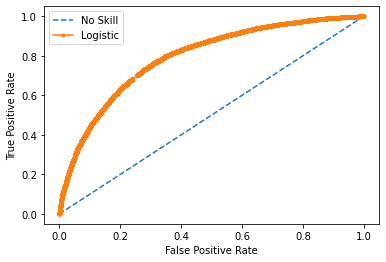

In [12]:
lr = LogisticRegression(
                        C= 0.000250
)
model = lr.fit(df_bow_train, df_train['score'])
logging.info("Fit de la réfression Logistic réalisée")
score = model.score(df_bow_validate, df_validate['score'])
print(f"Le score sur l'échantillon de validation est {score}.")

# Plot the ROC
# Probabilities for the no-skill
ns_probs = [0 for _ in range(len(df_validate['score']))]
# Probabilities for the Logistic Regression 
lr_probs = model.predict_proba(df_bow_validate)
# keep probabilities for the positive outcome only
lr_probs = lr_probs[:, 1]
# calculate scores
ns_auc = roc_auc_score(df_validate['score'], ns_probs)
lr_auc = roc_auc_score(df_validate['score'], lr_probs)
# summarize scores
print('No Skill: ROC AUC=%.3f' % (ns_auc))
print('Logistic: ROC AUC=%.3f' % (lr_auc))
# calculate roc curves
ns_fpr, ns_tpr, _ = roc_curve(df_validate['score'], ns_probs)
lr_fpr, lr_tpr, _ = roc_curve(df_validate['score'], lr_probs)
# plot the roc curve for the model
plt.plot(ns_fpr, ns_tpr, linestyle='--', label='No Skill')
plt.plot(lr_fpr, lr_tpr, marker='.', label='Logistic')
# axis labels
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
# show the legend
plt.legend()
# show the plot
plt.show()


# Free some memory
del(df_train)
del(df_validate)
del(df_bow_train)
del(df_bow_validate)

In [13]:
df_test = pd.read_pickle(path + FILE_DF_TEST + f"-{COEF}.pkl")

# reduce to fit in memory
sample_coef = 0.01
sample = df_test.sample(
                        n= int(sample_coef * len(df_test)),
                        replace= False
).index

score = model.score(df_bow.loc[sample], df_test.loc[sample, 'score'])
print(f"Le score sur l'échantillon de validation est {score}.")

Le score sur l'échantillon de validation est 0.6785415504740658.


[[0.86625282 0.13374718]
 [0.50482359 0.49517641]]


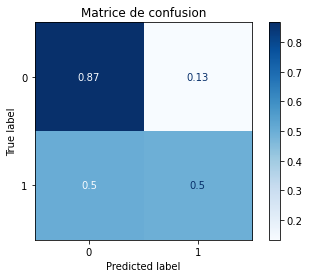

In [20]:
disp = plot_confusion_matrix(
                                model,
                                df_bow.loc[sample],
                                df_test.loc[sample, 'score'],
                                cmap= plt.cm.Blues,
                                normalize= 'true'
)
disp.ax_.set_title(f"Matrice de confusion")
print(disp.confusion_matrix)

plt.show()